# Previsão de Rating
Acredito que essa previsão seja extremamente difícil, devido a como cada tipo de pessoa da as notas, sem contar que acredito que é muito mais fácil alguém dar uma nota "ruim" do que "boa", afim de reclamar de algo.

Acredito ainda que clientes que pagam mais caro possuam uma exigência maior do que os que pagam mais caro, afinal, quanto mais se paga, mais cuidado, espaço, conforto, etc. se requer.

**Talvez fazer por multiclass**, em intervalos de 0-1, 1-2, 2-3, 3-4, 4-4,5 e 4,5-5. 

### Bairros Seguros e Perigosos

In [ ]:
df_treatment.review_scores_rating.describe()

count    34405.000000
mean         4.806563
std          0.375931
min          0.000000
25%          4.770000
50%          4.920000
75%          5.000000
max          5.000000
Name: review_scores_rating, dtype: float64

In [ ]:
colunas_desejadas = [
    'id', 'host_is_superhost', 'latitude', 'longitude', 'accommodates', 
    'bathrooms', 'bedrooms', 'beds', 'number_of_reviews', 
    'review_scores_rating', 'price_cleaned', 'minimum_nights', 'room_type', 'len_description', 'len_name'
]

dfs_por_bairro = {
    nome_grupo: dados[colunas_desejadas].dropna().query("review_scores_rating >= 0 and number_of_reviews >=5")
    for nome_grupo, dados in df_treatment.groupby('bairro_perigoso')
}

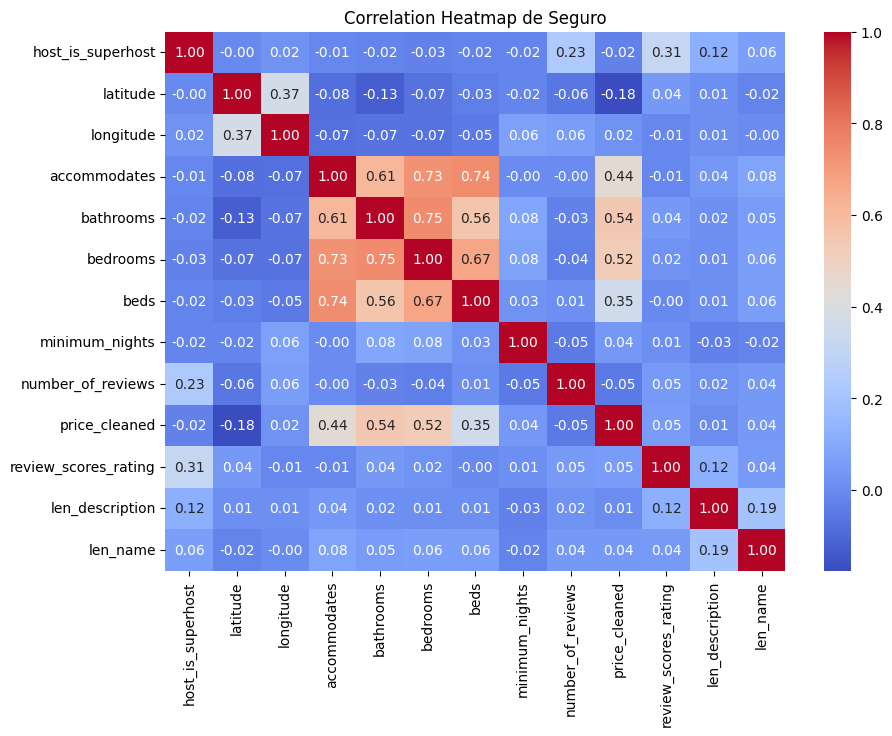

19329


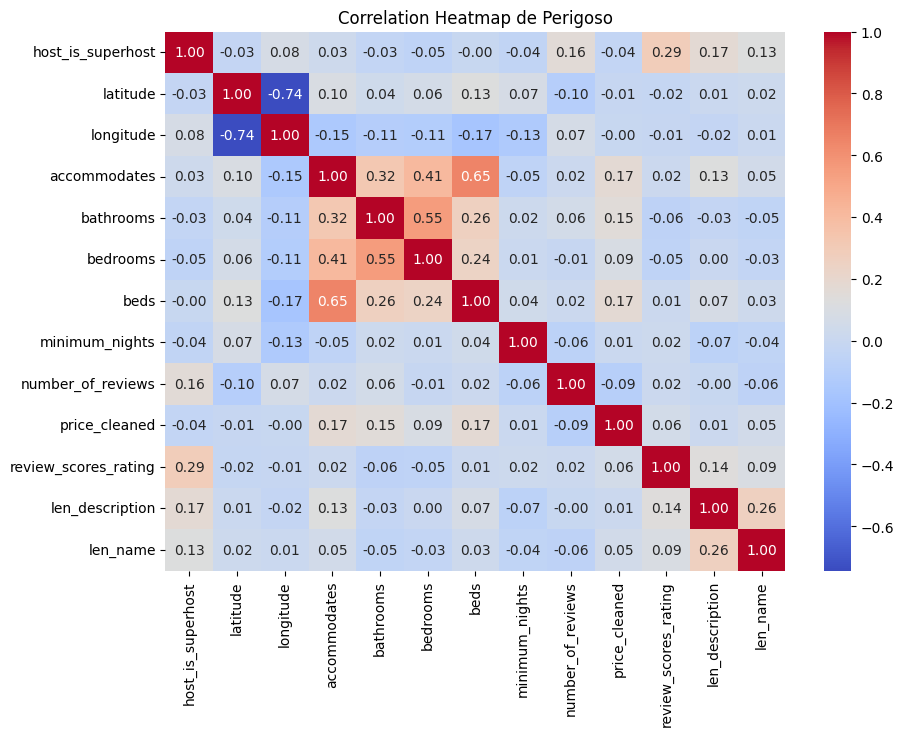

1634


In [ ]:
for bairro, df_grupo in dfs_por_bairro.items():
    tipo_bairro = 'Seguro' if bairro == 0 else 'Perigoso'
    plt.figure(figsize=(10, 7))
    corr = df_grupo[[
        'host_is_superhost', 'latitude', 'longitude', 'accommodates', 
        'bathrooms', 'bedrooms', 'beds', 'minimum_nights', 'number_of_reviews', 
        'price_cleaned', 'review_scores_rating', 'len_description', 'len_name'
        # 'Todo o espaço', 'Quarto privativo', 'Quarto compartilhado'
        ]].dropna().corr()

    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
    plt.title(f'Correlation Heatmap de {tipo_bairro}' )
    plt.show()
    print(len(df_grupo))

In [ ]:
cat_cols = ['host_is_superhost', 'room_type']
num_cols = ['latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'number_of_reviews', 'price_cleaned']#, 'len_description', 'len_name']

In [ ]:
precomputador_arvore = ColumnTransformer(
    transformers=[
        ('cat', preprocessing.OneHotEncoder(sparse_output=False), cat_cols),
        ('num', 'passthrough', num_cols)
    ],
    remainder='drop')

In [ ]:
modelos_por_bairro = {
    "arvore_normal": {},
    "arvore_xgboost": {},
    "lasso": {}
}

predicoes_por_bairro = {
    "arvore_normal": {},
    "arvore_xgboost": {},
    "lasso": {}
}

metricas_por_bairro = {
    "arvore_normal": {},
    "arvore_xgboost": {},
    "lasso": {}
}

#### Arvore Regressora

In [ ]:
from sklearn.metrics import mean_absolute_error

MODELO_ATUAL = "arvore_normal"

for nome_grupo, df_grupo in dfs_por_bairro.items():
    status_bairro = "Seguro" if nome_grupo == 0 else "Perigoso"
    print(f"\n--- Treinando {MODELO_ATUAL} para o grupo: {status_bairro} ---")
    
    df_grupo.dropna(inplace=True)
    
    X_grupo = df_grupo.drop(columns=['review_scores_rating'])
    y_grupo = df_grupo['review_scores_rating'].values
    
    X_train, X_test, y_train, y_test = train_test_split(
        X_grupo, y_grupo, test_size=0.2, random_state=RANDOM_SEED
    )
    
    pipeline_atual = Pipeline(steps=[
        ('pre-processamento', precomputador_arvore),
        ('modelo', clone(arvore_regressora))
    ])
    
    pipeline_atual.fit(X_train, y_train)
    y_pred_arvore = pipeline_atual.predict(X_test)

    r2 = r2_score(y_test, y_pred_arvore)
    mae = mean_absolute_error(y_test, y_pred_arvore)
    print(f"R² Score: {r2:.4f}")
    print(f"Mean absolut error: {mae:.4f}")
    
    modelos_por_bairro[MODELO_ATUAL][status_bairro] = pipeline_atual
    
    predicoes_por_bairro[MODELO_ATUAL][status_bairro] = {
        'y_test': y_test,
        'y_pred': y_pred_arvore
    }
    
    metricas_por_bairro[MODELO_ATUAL][status_bairro] = {
        'R2': r2, 
        'MAE': mae
    }


--- Treinando arvore_normal para o grupo: Seguro ---


R² Score: 0.1079
Mean absolut error: 0.1241

--- Treinando arvore_normal para o grupo: Perigoso ---
R² Score: 0.1646
Mean absolut error: 0.1209


#### XGBoost

In [ ]:
from xgboost import XGBRegressor

MODELO_ATUAL = "arvore_xgboost"

for nome_grupo, df_grupo in dfs_por_bairro.items():
    status_bairro = "Seguro" if nome_grupo == 0 else "Perigoso"
    print(f"\n--- Treinando {MODELO_ATUAL} para o grupo: {status_bairro} ---")
    df_grupo.dropna(inplace=True)
    
    X_grupo = df_grupo.drop(columns=['review_scores_rating'])
    y_grupo = df_grupo['review_scores_rating'].values
    
    X_train, X_test, y_train, y_test = train_test_split(
        X_grupo, y_grupo, test_size=0.2, random_state=RANDOM_SEED
    )
    precomputador_do_grupo = clone(precomputador_arvore)
    
    pipeline_xgb = Pipeline(steps=[
        ('pre-processamento', precomputador_do_grupo),
        ('modelo', XGBRegressor(
            n_estimators=200,
            max_depth=5,
            learning_rate=0.01,
            random_state=RANDOM_SEED,
            n_jobs=-1
        ))
    ])
    
    pipeline_xgb.fit(X_train, y_train)
    y_pred_xgb = pipeline_xgb.predict(X_test)

    r2 = r2_score(y_test, y_pred_xgb)
    mae = root_mean_squared_error(y_test, y_pred_xgb)
    print(f"R² Score: {r2:.4f}")
    print(f"Mean absolut error: {mae:.4f}\n")
    
    modelos_por_bairro[MODELO_ATUAL][nome_grupo] = pipeline_xgb
    predicoes_por_bairro[MODELO_ATUAL][nome_grupo] = {'y_test': y_test, 'y_pred': y_pred_xgb}
    metricas_por_bairro[MODELO_ATUAL][nome_grupo] = {'R2': r2, 'MAE': mae}


--- Treinando arvore_xgboost para o grupo: Seguro ---


R² Score: 0.1343
Mean absolut error: 0.1729


--- Treinando arvore_xgboost para o grupo: Perigoso ---
R² Score: 0.1995
Mean absolut error: 0.1622



In [ ]:
import pandas as pd
import plotly.express as px

nome_do_grupo = 0

y_real = predicoes_por_bairro['arvore_xgboost'][nome_do_grupo]['y_test']
y_previsto = predicoes_por_bairro['arvore_xgboost'][nome_do_grupo]['y_pred']

df_grupo_original = dfs_por_bairro[nome_do_grupo].dropna()
X_grupo = df_grupo_original.drop(columns=['review_scores_rating'])
y_grupo = df_grupo_original['review_scores_rating'].values

_, X_test_grupo, _, _ = train_test_split(
    X_grupo, y_grupo, test_size=0.2, random_state=RANDOM_SEED
)

df_grupo = pd.DataFrame({
    'id_imovel': X_test_grupo['id'], 
    'rating_real': y_real,            
    'rating_previsto': y_previsto     
})

df_grupo.reset_index(drop=True, inplace=True)
df_grupo['erro absoluto'] = (df_grupo['rating_previsto'] - df_grupo['rating_real'])
df_grupo['erro (%)'] = ((df_grupo['rating_real'] - df_grupo['rating_previsto']).abs() / df_grupo['rating_real'])*100

fig = px.line(df_grupo, y=['rating_real', 'rating_previsto'], 
              title=f"Nota Real vs Previsto - {nome_do_grupo}")
fig.update_layout(
    width=1500,
    height=800
)
fig.show()

print(f"Exemplos com erro >= 10% para {nome_do_grupo}:")
print(df_grupo[df_grupo['erro (%)'] >= 10].head())

Exemplos com erro >= 10% para 0:
               id_imovel  rating_real  rating_previsto  erro absoluto  \
31   1574086163993252433         4.33         4.780931       0.450931   
48               1973108         4.20         4.786925       0.586925   
67   1493040544191491009         4.22         4.768516       0.548516   
147  1321349919564902505         4.29         4.740907       0.450907   
156  1619171068107270190         4.14         4.870518       0.730518   

      erro (%)  
31   10.414100  
48   13.974412  
67   12.998000  
147  10.510646  
156  17.645367  


#### Lasso

In [ ]:
MODELO_ATUAL = "lasso"

for nome_grupo, df_grupo in dfs_por_bairro.items():
    status_bairro = "Seguro" if nome_grupo == 0 else "Perigoso"
    print(f"\n--- Treinando {MODELO_ATUAL} para o grupo: {status_bairro} ---")
    
    X_grupo = df_grupo.drop(columns=['review_scores_rating'])
    y_grupo = df_grupo['review_scores_rating'].values
    
    X_train, X_test, y_train, y_test = train_test_split(
        X_grupo, y_grupo, test_size=0.2, random_state=RANDOM_SEED
    )
    
    precomputador_do_grupo = ColumnTransformer(
        transformers=[
            ('num', RobustScaler(), num_cols),
            ('cat', OneHotEncoder(sparse_output=False), cat_cols)
        ],
        remainder='drop'
    )
    
    pipeline_atual = Pipeline(steps=[
        ('pre-processamento', precomputador_do_grupo),
        ('polinomial', PolynomialFeatures(degree=2, include_bias=False)),
        ('modelo', Lasso(alpha=0.001, max_iter=5000))
    ])
    
    pipeline_atual.fit(X_train, y_train)
    y_pred_lasso = pipeline_atual.predict(X_test)

    r2 = r2_score(y_test, y_pred_lasso)
    mae = mean_absolute_error(y_test, y_pred_lasso)
    print(f"R² Score: {r2:.4f}")
    print(f"Mean absolut error: {mae:.4f}\n")
    
    modelos_pricing[CASO][MODELO_ATUAL][nome_grupo] = pipeline_atual
    predicoes_pricing[CASO][MODELO_ATUAL][nome_grupo] = {
        'y_test': y_test,
        'y_pred': y_pred_lasso
    }
    metricas_pricing[CASO][MODELO_ATUAL][nome_grupo] = {'R2': r2, 'MAE': mae}


--- Treinando lasso para o grupo: Seguro ---
R² Score: 0.1131
Mean absolut error: 0.1241


--- Treinando lasso para o grupo: Perigoso ---
R² Score: 0.1333
Mean absolut error: 0.1244



In [ ]:
from sklearn.dummy import DummyRegressor
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)


print("R² Score do Dummy (Média):", r2_score(y_test, pred_dummy))
print(f"MAE do Dummy (Média): {mean_absolute_error(y_test, pred_dummy):.2f}")

R² Score do Dummy (Média): -0.005982445605980491
MAE do Dummy (Média): 0.14


### Quartos

In [ ]:
colunas_desejadas = ['id', 'host_is_superhost', 'latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'number_of_reviews', 'review_scores_rating', 'price_cleaned', 'minimum_nights', 'bairro_perigoso', 'len_description', 'len_name']

dfs_por_quartos = {
    nome_grupo: dados[colunas_desejadas].dropna().query("review_scores_rating >= 4 and number_of_reviews >=10")
    for nome_grupo, dados in df_treatment.groupby('room_type')
}

In [ ]:
room_trad.values()

dict_values(['Todo o espaço', 'Quarto privativo', 'Quarto compartilhado'])

In [ ]:
cat_cols = ['host_is_superhost', 'bairro_perigoso']
num_cols = ['latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'number_of_reviews', 'price_cleaned', 'len_description', 'len_name']

In [ ]:
precomputador_arvore = ColumnTransformer(
    transformers=[
        ('cat', preprocessing.OneHotEncoder(sparse_output=False), cat_cols),
        ('num', 'passthrough', num_cols)
    ],
    remainder='drop')

In [ ]:
modelos_por_quarto = {
    "arvore_normal": {},
    "arvore_xgboost": {},
    "lasso": {}
}

predicoes_por_quarto = {
    "arvore_normal": {},
    "arvore_xgboost": {},
    "lasso": {}
}

metricas_por_quarto = {
    "arvore_normal": {},
    "arvore_xgboost": {},
    "lasso": {}
}

In [ ]:
MODELO_ATUAL = "arvore_normal"

for nome_grupo, df_grupo in dfs_por_quartos.items():
    print(f"\n--- Treinando {MODELO_ATUAL} para o grupo: {nome_grupo} ---")
    
    X_grupo = df_grupo.drop(columns=['review_scores_rating'])
    y_grupo = df_grupo['review_scores_rating'].values
    
    X_train, X_test, y_train, y_test = train_test_split(
        X_grupo, y_grupo, test_size=0.2, random_state=RANDOM_SEED
    )
    
    pipeline_atual = Pipeline(steps=[
        ('pre-processamento', precomputador_arvore),
        ('modelo', clone(arvore_regressora))
    ])
    
    pipeline_atual.fit(X_train, y_train)
    y_pred_arvore = pipeline_atual.predict(X_test)

    r2 = r2_score(y_test, y_pred_arvore)
    mae = mean_absolute_error(y_test, y_pred_arvore)
    print(f"R² Score: {r2:.4f}")
    print(f"Mean absolute error: {mae:.4f}")
    
    modelos_por_quarto[MODELO_ATUAL][nome_grupo] = pipeline_atual
    predicoes_por_quarto[MODELO_ATUAL][nome_grupo] = {
        'y_test': y_test,
        'y_pred': y_pred_arvore
    }
    metricas_por_quarto[MODELO_ATUAL][nome_grupo] = {'R2': r2, 'mae': mae}


--- Treinando arvore_normal para o grupo: Quarto compartilhado ---
R² Score: -0.0935
Mean absolute error: 0.2031

--- Treinando arvore_normal para o grupo: Quarto privativo ---
R² Score: 0.0589
Mean absolute error: 0.1439

--- Treinando arvore_normal para o grupo: Todo o espaço ---
R² Score: 0.1856
Mean absolute error: 0.1021


In [ ]:
from xgboost import XGBRegressor

MODELO_ATUAL = "arvore_xgboost"

for nome_grupo, df_grupo in dfs_por_quartos.items():
    print(f"\n--- Treinando {MODELO_ATUAL} para o grupo: {nome_grupo} ---")
    df_grupo.dropna(inplace=True)
    
    X_grupo = df_grupo.drop(columns=['review_scores_rating'])
    y_grupo = df_grupo['review_scores_rating'].values
    
    X_train, X_test, y_train, y_test = train_test_split(
        X_grupo, y_grupo, test_size=0.2, random_state=RANDOM_SEED
    )
    precomputador_do_grupo = clone(precomputador_arvore)
    
    pipeline_xgb = Pipeline(steps=[
        ('pre-processamento', precomputador_do_grupo),
        ('modelo', XGBRegressor(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.1,
            random_state=RANDOM_SEED,
            n_jobs=-1
        ))
    ])
    
    pipeline_xgb.fit(X_train, y_train)
    y_pred_xgb = pipeline_xgb.predict(X_test)

    r2 = r2_score(y_test, y_pred_xgb)
    mae = mean_absolute_error(y_test, y_pred_xgb)
    print(f"R² Score: {r2:.4f}")
    print(f"Mean absolut error: {mae:.4f}\n")
    
    modelos_por_quarto[MODELO_ATUAL][nome_grupo] = pipeline_xgb
    predicoes_por_quarto[MODELO_ATUAL][nome_grupo] = {'y_test': y_test, 'y_pred': y_pred_xgb}
    metricas_por_quarto[MODELO_ATUAL][nome_grupo] = {'R2': r2, 'RMSE': mae}


--- Treinando arvore_xgboost para o grupo: Quarto compartilhado ---
R² Score: 0.2225
Mean absolut error: 0.1554


--- Treinando arvore_xgboost para o grupo: Quarto privativo ---
R² Score: -0.2115
Mean absolut error: 0.1567


--- Treinando arvore_xgboost para o grupo: Todo o espaço ---
R² Score: 0.2198
Mean absolut error: 0.0995



In [ ]:
MODELO_ATUAL = "lasso"

for nome_grupo, df_grupo in dfs_por_quartos.items():
    print(f"\n--- Treinando {MODELO_ATUAL} para o grupo: {nome_grupo} ---")
    df_grupo.dropna(inplace=True)
    
    X_grupo = df_grupo.drop(columns=['review_scores_rating'])
    y_grupo = df_grupo['review_scores_rating'].values
    
    X_train, X_test, y_train, y_test = train_test_split(
        X_grupo, y_grupo, test_size=0.2, random_state=RANDOM_SEED
    )
    
    precomputador_do_grupo = ColumnTransformer(
        transformers=[
            ('num', RobustScaler(), num_cols),
            ('cat', OneHotEncoder(sparse_output=False), cat_cols)
        ],
        remainder='drop'
    )
    
    pipeline_atual = Pipeline(steps=[
        ('pre-processamento', precomputador_do_grupo),
        ('polinomial', PolynomialFeatures(degree=2, include_bias=False)),
        ('modelo', Lasso(alpha=0.89, max_iter=5000))
    ])
    
    pipeline_atual.fit(X_train, y_train)
    y_pred_lasso = pipeline_atual.predict(X_test)

    r2 = r2_score(y_test, y_pred_lasso)
    mae = mean_absolute_error(y_test, y_pred_lasso)
    print(f"R² Score: {r2:.4f}")
    print(f"Root mean squared error: {rmse:.4f}\n")
    
    modelos_por_quarto[MODELO_ATUAL][nome_grupo] = pipeline_atual
    predicoes_por_quarto[MODELO_ATUAL][nome_grupo] = {
        'y_test': y_test,
        'y_pred': y_pred_lasso
    }
    metricas_por_quarto[MODELO_ATUAL][nome_grupo] = {'R2': r2, 'MAE': mae}


--- Treinando lasso para o grupo: Quarto compartilhado ---
R² Score: -0.0906
Root mean squared error: 732.5021


--- Treinando lasso para o grupo: Quarto privativo ---
R² Score: -0.0060
Root mean squared error: 732.5021


--- Treinando lasso para o grupo: Todo o espaço ---
R² Score: -0.0005
Root mean squared error: 732.5021



### Preço

In [ ]:
colunas_desejadas = [
    'id', 'host_is_superhost', 'latitude', 'longitude', 'accommodates',
    'bathrooms', 'bedrooms', 'beds', 'number_of_reviews', 
    'review_scores_rating', 'price_cleaned', 'minimum_nights', 'bairro_perigoso', 'len_description', 'len_name'
]
limites = [0, 200, 400, 600, 1000]
nomes_faixas = ['Barato', 'Médio', 'Caro', 'Muito caro']

df_treatment['faixa_preco'] = pd.cut(
    df_treatment['price_cleaned'], 
    bins=limites, 
    labels=nomes_faixas
)

colunas_finais = colunas_desejadas + ['faixa_preco']

dfs_por_precos = {
    nome_grupo: dados[colunas_finais].dropna().query("review_scores_rating >= 4 and number_of_reviews >= 10")
    for nome_grupo, dados in df_treatment.groupby('faixa_preco', observed=False)
}

In [ ]:
cat_cols = ['bairro_perigoso']
num_cols = ['latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'price_cleaned', 'len_description', 'len_name']

In [ ]:
precomputador_arvore = ColumnTransformer(
    transformers=[
        ('cat', preprocessing.OneHotEncoder(sparse_output=False), cat_cols),
        ('num', 'passthrough', num_cols)
    ],
    remainder='drop')

In [ ]:
modelos_por_preco = {
    "arvore_normal": {},
    "arvore_xgboost": {},
    "lasso": {}
}

predicoes_por_preco = {
    "arvore_normal": {},
    "arvore_xgboost": {},
    "lasso": {}
}

metricas_por_preco = {
    "arvore_normal": {},
    "arvore_xgboost": {},
    "lasso": {}
}

In [ ]:
MODELO_ATUAL = "arvore_normal"

for nome_grupo, df_grupo in dfs_por_precos.items():
    print(f"\n--- Treinando {MODELO_ATUAL} para o grupo: {nome_grupo} ---")
    
    X_grupo = df_grupo.drop(columns=['review_scores_rating'])
    y_grupo = df_grupo['review_scores_rating'].values
    
    X_train, X_test, y_train, y_test = train_test_split(
        X_grupo, y_grupo, test_size=0.2, random_state=RANDOM_SEED
    )
    
    pipeline_atual = Pipeline(steps=[
        ('pre-processamento', precomputador_arvore),
        ('modelo', clone(arvore_regressora))
    ])
    
    pipeline_atual.fit(X_train, y_train)
    y_pred_arvore = pipeline_atual.predict(X_test)

    r2 = r2_score(y_test, y_pred_arvore)
    mae = root_mean_squared_error(y_test, y_pred_arvore)
    print(f"R² Score: {r2:.4f}")
    print(f"Mean absolute error: {rmse:.4f}")
    
    modelos_por_preco[MODELO_ATUAL][nome_grupo] = pipeline_atual
    predicoes_por_preco[MODELO_ATUAL][nome_grupo] = {
        'y_test': y_test,
        'y_pred': y_pred_arvore
    }
    metricas_por_preco[MODELO_ATUAL][nome_grupo] = {'R2': r2, 'MAE': mae}


--- Treinando arvore_normal para o grupo: Barato ---
R² Score: 0.0852
Mean absolute error: 732.5021

--- Treinando arvore_normal para o grupo: Médio ---
R² Score: 0.0364
Mean absolute error: 732.5021

--- Treinando arvore_normal para o grupo: Caro ---
R² Score: -0.0303
Mean absolute error: 732.5021

--- Treinando arvore_normal para o grupo: Muito caro ---
R² Score: 0.0264
Mean absolute error: 732.5021


In [ ]:
from xgboost import XGBRegressor

MODELO_ATUAL = "arvore_xgboost"

for nome_grupo, df_grupo in dfs_por_precos.items():
    print(f"\n--- Treinando {MODELO_ATUAL} para o grupo: {nome_grupo} ---")
    df_grupo.dropna(inplace=True)
    
    X_grupo = df_grupo.drop(columns=['review_scores_rating'])
    y_grupo = df_grupo['review_scores_rating'].values
    
    X_train, X_test, y_train, y_test = train_test_split(
        X_grupo, y_grupo, test_size=0.2, random_state=RANDOM_SEED
    )
    precomputador_do_grupo = clone(precomputador_arvore)
    
    pipeline_xgb = Pipeline(steps=[
        ('pre-processamento', precomputador_do_grupo),
        ('modelo', XGBRegressor(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.1,
            random_state=RANDOM_SEED,
            n_jobs=-1
        ))
    ])
    
    pipeline_xgb.fit(X_train, y_train)
    y_pred_xgb = pipeline_xgb.predict(X_test)

    r2 = r2_score(y_test, y_pred_xgb)
    mae = mean_absolute_error(y_test, y_pred_xgb)
    print(f"R² Score: {r2:.4f}")
    print(f"Root mean squared error: {mae:.4f}\n")
    
    modelos_por_preco[MODELO_ATUAL][nome_grupo] = pipeline_xgb
    predicoes_por_preco[MODELO_ATUAL][nome_grupo] = {'y_test': y_test, 'y_pred': y_pred_xgb}
    metricas_por_preco[MODELO_ATUAL][nome_grupo] = {'R2': r2, 'MAE': mae}


--- Treinando arvore_xgboost para o grupo: Barato ---


R² Score: 0.2623
Root mean squared error: 0.1316


--- Treinando arvore_xgboost para o grupo: Médio ---
R² Score: 0.0690
Root mean squared error: 0.1121


--- Treinando arvore_xgboost para o grupo: Caro ---
R² Score: 0.0057
Root mean squared error: 0.1165


--- Treinando arvore_xgboost para o grupo: Muito caro ---
R² Score: 0.0015
Root mean squared error: 0.1099



In [ ]:
MODELO_ATUAL = "lasso"

for nome_grupo, df_grupo in dfs_por_precos.items():
    print(f"\n--- Treinando {MODELO_ATUAL} para o grupo: {nome_grupo} ---")
    df_grupo.dropna(inplace=True)
    
    X_grupo = df_grupo.drop(columns=['review_scores_rating'])
    y_grupo = df_grupo['review_scores_rating'].values
    
    X_train, X_test, y_train, y_test = train_test_split(
        X_grupo, y_grupo, test_size=0.2, random_state=RANDOM_SEED
    )
    
    precomputador_do_grupo = ColumnTransformer(
        transformers=[
            ('num', RobustScaler(), num_cols),
            ('cat', OneHotEncoder(sparse_output=False), cat_cols)
        ],
        remainder='drop'
    )
    
    pipeline_atual = Pipeline(steps=[
        ('pre-processamento', precomputador_do_grupo),
        ('polinomial', PolynomialFeatures(degree=1, include_bias=False)),
        ('modelo', Lasso(alpha=0.89, max_iter=5000))
    ])
    
    pipeline_atual.fit(X_train, y_train)
    y_pred_lasso = pipeline_atual.predict(X_test)

    r2 = r2_score(y_test, y_pred_lasso)
    mae = mean_absolute_error(y_test, y_pred_lasso)
    print(f"R² Score: {r2:.4f}")
    print(f"Root mean squared error: {mae:.4f}\n")
    
    modelos_por_preco[MODELO_ATUAL][nome_grupo] = pipeline_atual
    predicoes_por_preco[MODELO_ATUAL][nome_grupo] = {
        'y_test': y_test,
        'y_pred': y_pred_lasso
    }
    metricas_por_preco[MODELO_ATUAL][nome_grupo] = {'R2': r2, 'MAE': mae}


--- Treinando lasso para o grupo: Barato ---
R² Score: -0.0065
Root mean squared error: 0.1574


--- Treinando lasso para o grupo: Médio ---
R² Score: -0.0009
Root mean squared error: 0.1182


--- Treinando lasso para o grupo: Caro ---
R² Score: -0.0000
Root mean squared error: 0.1161


--- Treinando lasso para o grupo: Muito caro ---
R² Score: -0.0002
Root mean squared error: 0.1098



A faixa de preço não influencia tanto

### Previsão por multiclass
 + Classe 1: < 4.0 (Acomodações ruins / Críticas)
 + Classe 2: 4.0 - 4.5 (Acomodações medianas, com problemas pontuais)
 + Classe 3: 4.5 - 4.75 (Acomodações boas)
 + Classe 4: 4.75 - 4.9 (Acomodações muito boas / Superhosts frequentes)
 + Classe 5: 4.9 - 5.0 (Acomodações excepcionais)

In [ ]:
df_treatment.review_scores_rating.describe()

count    34405.000000
mean         4.806563
std          0.375931
min          0.000000
25%          4.770000
50%          4.920000
75%          5.000000
max          5.000000
Name: review_scores_rating, dtype: float64

In [ ]:
colunas_desejadas = [
    'id', 'host_is_superhost', 'latitude', 'longitude', 'accommodates',
    'bathrooms', 'bedrooms', 'beds', 'number_of_reviews', 
    'review_scores_rating', 'price_cleaned', 'minimum_nights', 'bairro_perigoso', 'len_description', 'len_name'
]

In [ ]:
categorias = [['Ruins', 'Medianas', 'Boas', 'Muito boas', 'Excepcionais']]

bins = [-0.1, 4.0, 4.5, 4.75, 4.9, 5.01]

labels = [
    "Ruins",
    "Medianas",
    "Boas",
    "Muito boas",
    "Excepcionais",
]

df_multiclass = df_treatment[colunas_desejadas].copy()

df_multiclass["classe_acomodacao"] = pd.cut(
    df_multiclass["review_scores_rating"], bins=bins, labels=labels, right=False
)

df_multiclass.dropna(inplace=True)

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
cat_cols = ['bairro_perigoso']
num_cols = ['latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'price_cleaned', 'len_description', 'len_name']

In [ ]:
X = df_multiclass[cat_cols + num_cols]
y = df_multiclass['classe_acomodacao']

In [ ]:
df_multiclass.classe_acomodacao.value_counts()

classe_acomodacao
Excepcionais    15083
Muito boas       6694
Boas             3991
Medianas         1645
Ruins             581
Name: count, dtype: int64

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_SEED)

scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_model = SVC(kernel="linear", C=1.0, gamma="scale", decision_function_shape="ovo", random_state=RANDOM_SEED, class_weight='balanced') #talvez mudar one-to-one
svm_model.fit(X_train_scaled, y_train)

y_pred = svm_model.predict(X_test_scaled)

print("--- Relatório de Classificação ---")
print(classification_report(y_test, y_pred))

--- Relatório de Classificação ---
              precision    recall  f1-score   support

        Boas       0.18      0.09      0.12       794
Excepcionais       0.64      0.23      0.33      3004
    Medianas       0.07      0.14      0.09       328
  Muito boas       0.28      0.53      0.36      1374
       Ruins       0.03      0.25      0.05        99

    accuracy                           0.28      5599
   macro avg       0.24      0.25      0.19      5599
weighted avg       0.44      0.28      0.29      5599



In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, criterion='gini', random_state=RANDOM_SEED, class_weight='balanced')

rf_model.fit(X_train, y_train)

predictions = rf_model.predict(X_test)
probabilities = rf_model.predict_proba(X_test)

target_names = [str(cls) for cls in sorted(y.unique())] 
print(classification_report(y_test, predictions, target_names=target_names))

              precision    recall  f1-score   support

        Boas       0.27      0.04      0.07       794
Excepcionais       0.56      0.93      0.70      3004
    Medianas       0.32      0.03      0.05       328
  Muito boas       0.37      0.11      0.17      1374
       Ruins       0.00      0.00      0.00        99

    accuracy                           0.54      5599
   macro avg       0.30      0.22      0.20      5599
weighted avg       0.45      0.54      0.43      5599



In [ ]:
from sklearn.tree import DecisionTreeClassifier

decriontree_model = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_SEED, min_samples_leaf=5, class_weight='balanced')

decriontree_model.fit(X_train, y_train)

predictions = decriontree_model.predict(X_test)
probabilities = decriontree_model.predict_proba(X_test)

target_names = [str(cls) for cls in sorted(y.unique())] 
print(classification_report(y_test, predictions, target_names=target_names))

              precision    recall  f1-score   support

        Boas       0.16      0.24      0.19       794
Excepcionais       0.59      0.31      0.41      3004
    Medianas       0.07      0.20      0.10       328
  Muito boas       0.28      0.30      0.29      1374
       Ruins       0.03      0.11      0.04        99

    accuracy                           0.29      5599
   macro avg       0.23      0.23      0.21      5599
weighted avg       0.41      0.29      0.32      5599



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
import xgboost as xgb

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_encoded
)

sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

xgb_model = xgb.XGBClassifier(
    objective='multi:softprob', 
    num_class=5, 
    random_state=RANDOM_SEED
)

xgb_model.fit(X_train, y_train, sample_weight=sample_weights)

,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method

In [ ]:
y_pred_numerico = xgb_model.predict(X_test)

y_pred_texto = label_encoder.inverse_transform(y_pred_numerico)

y_test_texto = label_encoder.inverse_transform(y_test)

resultados = pd.DataFrame({
    'Real': y_test_texto,
    'Previsão do Modelo': y_pred_texto
})

print("Amostra das Previsões:")
print(resultados.head(10))

print("\n" + "="*50 + "\n")

print("Relatório de Classificação:")
print(classification_report(y_test_texto, y_pred_texto))

Amostra das Previsões:
           Real Previsão do Modelo
0  Excepcionais       Excepcionais
1  Excepcionais       Excepcionais
2      Medianas       Excepcionais
3  Excepcionais       Excepcionais
4  Excepcionais               Boas
5  Excepcionais       Excepcionais
6  Excepcionais         Muito boas
7          Boas               Boas
8  Excepcionais       Excepcionais
9  Excepcionais       Excepcionais


Relatório de Classificação:
              precision    recall  f1-score   support

        Boas       0.18      0.23      0.20       798
Excepcionais       0.65      0.48      0.55      3017
    Medianas       0.08      0.14      0.10       329
  Muito boas       0.29      0.33      0.31      1339
       Ruins       0.04      0.08      0.05       116

    accuracy                           0.38      5599
   macro avg       0.25      0.25      0.24      5599
weighted avg       0.45      0.38      0.41      5599

